## Same-seed experiment: full velocity vs no mesoscale (W2.0)

The same particles (same seed, positions, depths and start time) are advected by two velocity fields:
* `full`   : original Mercator UVW (as in `Run_parcels_UVW_3`)
* `noMeso` : implicit-filtered UVW, W2.0 (as in `Run_parcels_UVW_3_noMeso`)

Order: **1** parameters → **2** release polygon → **3** fieldsets → **4** wet band → **5** seeding (once) → **6** land check → **7** run each experiment → **8** compare

## 1. Parameters

In [1]:
num_particles = 100
run_time_days = 100
time_step_minutes = 20
out_put_step_hours = 6

depth_min = 0
depth_max = 7

offset = 1
ref_date = "1993-01-01"
#reproducibility: ONE seed shared by both experiments
rdm_seed = 14

Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"

# the only thing that changes between experiments is the velocity files
experiments = {
    "full": {
        "U": "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW/U_1993-01c.nc",
        "V": "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW/V_1993-01c.nc",
        "W": "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW/W_1993-01fc.nc",
    },
    "noMeso": {
        "U": "/work/bk1450/b383184/Amazon/Mercator/implicit_run/output/W2.0/U_1993-01c_W2.0.nc",
        "V": "/work/bk1450/b383184/Amazon/Mercator/implicit_run/output/W2.0/V_1993-01c_W2.0.nc",
        "W": "/work/bk1450/b383184/Amazon/Mercator/implicit_run/output/W2.0/W_1993-01c_W2.0.nc",
    },
}

In [2]:
import numpy as np
from datetime import timedelta
from parcels import FieldSet, ParticleSet, AdvectionRK4_3D

out_path = f'tracks_sameseed_{rdm_seed}/' #path to store the particle zarrs

start_time = np.datetime64(ref_date) + np.timedelta64(offset, "D")
start_time

np.datetime64('1993-01-02')

## 2. Release polygon

In [3]:
# --- release polygon: green band (from release_polygon_map.ipynb) ---
vertices = {
    "A":  (-49.916,  1.166),   # Amazon coast  - start of release line
    "B":  (-49, -0.16),
    "B'": (-48.3,-0.2),
    "C":  (-48.5,-0.75),
    "C'": (-48.45,-1.05),
    "D":  (-48.12, -0.73 ),   # Para coast    - line prolonged SE to Para bank
    "D'": (-47.8,   -0.6  ),   # seaward corner off B (pushed NE)
    "A'": (-49.250,  1.610),   # seaward corner off A (0.8 deg perpendicular)
}

# build the closed ring (repeat the first point at the end)
_pts = list(vertices.values())
green_lons = [p[0] for p in _pts] + [_pts[0][0]]
green_lats = [p[1] for p in _pts] + [_pts[0][1]]

## 3. Fieldsets (one per experiment, same settings as Run_parcels_UVW_3)

In [4]:
loop_period = timedelta(days=31)

def make_fieldset(files):
    filenames = {
        v: {"data": files[v], "lon": Hgr, "lat": Hgr, "depth": files["W"]}
        for v in ["U", "V", "W"]
    }
    variables = {"U": "vozocrtx", "V": "vomecrty", "W": "vovecrtz"}
    dims = {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"}
    dimensions = {"U": dims, "V": dims, "W": dims}

    return FieldSet.from_nemo(
        filenames,
        variables,
        dimensions,
        deferred_load=True,
        allow_time_extrapolation=False,
        time_periodic=loop_period,
    )

fieldsets = {name: make_fieldset(files) for name, files in experiments.items()}
fieldsets

{'full': <FieldSet>
     fields:
         <Field>
             name            : 'U'
             grid            : CurvilinearZGrid(lon=array([[-94.96, -94.88, -94.79, ...,  9.79,  9.88,  9.96],
                [-94.96, -94.88, -94.79, ...,  9.79,  9.88,  9.96],
                [-94.96, -94.88, -94.79, ...,  9.79,  9.88,  9.96],
                ...,
                [-94.96, -94.88, -94.80, ...,  9.80,  9.89,  9.97],
                [-94.96, -94.88, -94.80, ...,  9.81,  9.89,  9.97],
                [-94.96, -94.88, -94.80, ...,  9.81,  9.89,  9.97]], shape=(499, 1260), dtype=float32), lat=array([[-9.91, -9.91, -9.91, ..., -9.91, -9.91, -9.91],
                [-9.83, -9.83, -9.83, ..., -9.83, -9.83, -9.83],
                [-9.74, -9.74, -9.74, ..., -9.74, -9.74, -9.74],
                ...,
                [ 29.80,  29.80,  29.80, ...,  29.84,  29.84,  29.84],
                [ 29.87,  29.87,  29.87, ...,  29.91,  29.91,  29.91],
                [ 29.94,  29.94,  29.94, ...,  29.98, 

## 4. Wet release band (model land mask, same grid for both)

In [5]:
# mbathy (Zgr) is the number of wet levels at each T point, i.e. NEMO's own land mask.
# Both experiments share Hgr/Zgr/depthw, so the wet band is computed once.
import xarray as xr
from shapely.geometry import Polygon
from shapely.ops import unary_union

_h  = xr.open_dataset(Hgr)
_z  = xr.open_dataset(Zgr)
glamf = _h.glamf.isel(t=0).values          # f points = cell corners
gphif = _h.gphif.isel(t=0).values
mbathy = _z.mbathy.isel(t=0).values        # wet levels per T column (0 = land)
depthw = xr.open_dataset(experiments["full"]["W"]).depthw.values

kmin = int(np.searchsorted(depthw, depth_max))   # levels needed to hold depth_max
band = Polygon(zip(green_lons[:-1], green_lats[:-1]))
bl, bs, br, bn = band.bounds

# index window around the band, so we only walk a few hundred cells
_in = (glamf >= bl-0.2) & (glamf <= br+0.2) & (gphif >= bs-0.2) & (gphif <= bn+0.2)
_j, _i = np.where(_in)
j0, j1, i0, i1 = _j.min(), _j.max(), _i.min(), _i.max()

# NEMO/parcels convention: T cell (j,i) has corners f(j-1,i-1)..f(j,i)
wet_cells = []
for j in range(j0+1, j1+1):
    for i in range(i0+1, i1+1):
        if mbathy[j, i] < kmin:
            continue
        q = Polygon([(glamf[j-1, i-1], gphif[j-1, i-1]), (glamf[j-1, i], gphif[j-1, i]),
                     (glamf[j,   i  ], gphif[j,   i  ]), (glamf[j,   i-1], gphif[j,   i-1])])
        if q.intersects(band):
            wet_cells.append(q)

wet_band = band.intersection(unary_union(wet_cells))
if wet_band.geom_type == 'MultiPolygon':                 # keep the main lobe
    wet_band = max(wet_band.geoms, key=lambda g: g.area)

wet_lons, wet_lats = np.array(wet_band.exterior.coords).T
print(f"band {band.area:.3f} deg^2 -> wet band {wet_band.area:.3f} deg^2 "
      f"({100*wet_band.area/band.area:.1f}% kept, {len(wet_lons)-1} vertices)")

band 1.778 deg^2 -> wet band 1.775 deg^2 (99.8% kept, 20 vertices)


## 5. Seeding — done ONCE, reused by both experiments

In [6]:
# uniform seeding inside the wet band (rejection sampling in its bounding box)
from shapely.geometry import Point
from shapely.prepared import prep

np.random.seed(rdm_seed)   # set the seed right before drawing the random numbers

_wb = prep(wet_band)
wl, ws, wr, wn = wet_band.bounds

start_lon = np.empty(num_particles)
start_lat = np.empty(num_particles)
n = 0
while n < num_particles:
    batch = max(num_particles - n, 1) * 3          # over-sample, most fall outside
    x = np.random.uniform(wl, wr, size=batch)
    y = np.random.uniform(ws, wn, size=batch)
    keep = np.fromiter((_wb.contains(Point(a, b)) for a, b in zip(x, y)),
                       dtype=bool, count=batch)
    x, y = x[keep], y[keep]
    take = min(len(x), num_particles - n)
    start_lon[n:n+take] = x[:take]
    start_lat[n:n+take] = y[:take]
    n += take

start_depth = np.random.uniform(depth_min, depth_max, size=num_particles)
start_times = np.datetime64(start_time)

print(start_lon[:3], start_lat[:3], start_depth[:3])

[-49.89897266 -48.83024504 -47.94270813] [ 1.17682462  0.14595272 -0.55273776] [0.18563385 1.00459348 2.8713776 ]


## 6. Land check (on both fieldsets)

In [7]:
# Land velocities are zeroed on load, so an exactly-zero UVW means a dry cell.
for name, fs in fieldsets.items():
    fs.computeTimeChunk(fs.U.grid.time[0], 1)
    _t = fs.U.grid.time[0]
    _dry = sum(fs.UVW[_t, d, la, lo] == (0.0, 0.0, 0.0)
               for lo, la, d in zip(start_lon, start_lat, start_depth))
    print(f"{name}: {_dry}/{num_particles} particles seeded on land")
    assert _dry == 0, f"{name}: some particles are on land - widen kmin or check the mask" 

full: 0/100 particles seeded on land
noMeso: 0/100 particles seeded on land


## 7. Run both experiments with the same starting positions

In [8]:
##check the error
def CheckError(particle, fieldset, time):
    if particle.state >= 50:  # This captures all Errors
        particle.delete()

In [9]:
out_files = {}
for name, fs in fieldsets.items():
    print(f"--- running {name} ---")
    pset = ParticleSet(
        fieldset=fs,
        lon=start_lon,        # same arrays for both runs
        lat=start_lat,
        depth=start_depth,
        time=start_times,
    )

    out_fn = f'Parcels_run_{rdm_seed}_{name}_{start_time}.zarr'
    out_files[name] = out_path + out_fn

    output_file = pset.ParticleFile(
        name=out_files[name],
        outputdt=timedelta(hours=out_put_step_hours),
        chunks=(num_particles, int(run_time_days*24/out_put_step_hours/4)),
    )

    pset.execute(
        [AdvectionRK4_3D, CheckError],
        runtime=timedelta(days=run_time_days),
        dt=timedelta(minutes=time_step_minutes),
        output_file=output_file,
    )

out_files

--- running full ---
INFO: Output files are stored in tracks_sameseed_14/Parcels_run_14_full_1993-01-02.zarr.
100%|██████████| 8640000.0/8640000.0 [08:28<00:00, 17004.41it/s]
--- running noMeso ---
INFO: Output files are stored in tracks_sameseed_14/Parcels_run_14_noMeso_1993-01-02.zarr.
100%|██████████| 8640000.0/8640000.0 [08:04<00:00, 17851.12it/s]


{'full': 'tracks_sameseed_14/Parcels_run_14_full_1993-01-02.zarr',
 'noMeso': 'tracks_sameseed_14/Parcels_run_14_noMeso_1993-01-02.zarr'}

## 8. Compare

In [10]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ds = {name: xr.open_zarr(f).compute() for name, f in out_files.items()}

# sanity check: the first output must be identical in both runs
for v in ["lon", "lat", "z"]:
    same = np.allclose(ds["full"][v].isel(obs=0), ds["noMeso"][v].isel(obs=0), equal_nan=True)
    print(f"initial {v} identical: {same}")

initial lon identical: True
initial lat identical: True
initial z identical: True


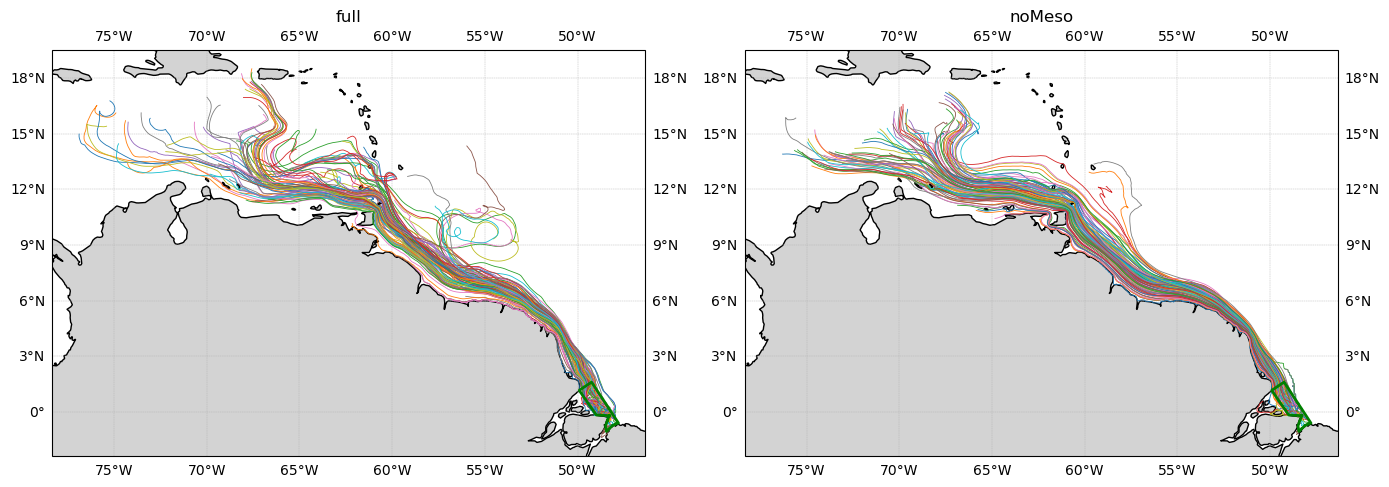

In [11]:
# trajectories side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6), subplot_kw={"projection": ccrs.PlateCarree()},
                         sharex=True, sharey=True)
for ax, (name, d) in zip(axes, ds.items()):
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.coastlines(resolution='50m')
    ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)
    for ii in range(d.sizes["trajectory"]):
        ax.plot(d.lon[ii], d.lat[ii], lw=0.6, transform=ccrs.PlateCarree())
    ax.plot(wet_lons, wet_lats, color='green', lw=2, transform=ccrs.PlateCarree())
    ax.set_title(name)
plt.tight_layout()
plt.show()

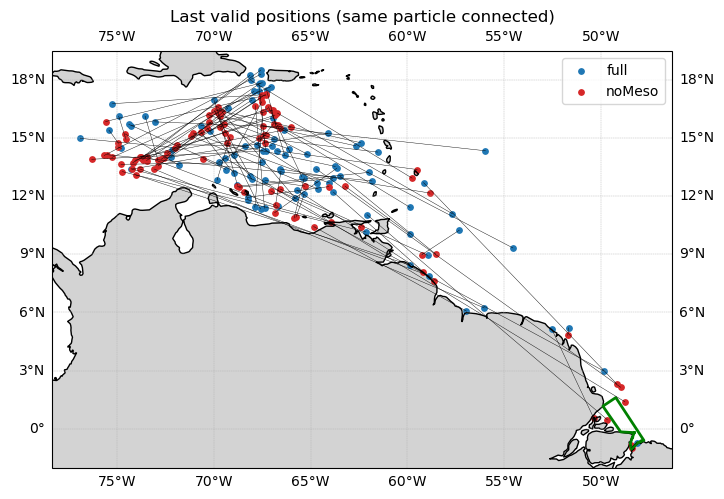

In [12]:
# last valid position of every particle (works for deleted and surviving particles)
def last_position(d):
    valid = d.lat.notnull().values                              # (trajectory, obs)
    idx = np.where(valid, np.arange(d.sizes["obs"]), -1).max(axis=1)
    it = np.arange(d.sizes["trajectory"])
    return d.lon.values[it, idx], d.lat.values[it, idx]

ends = {name: last_position(d) for name, d in ds.items()}

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.coastlines(resolution='50m')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)
ax.plot(wet_lons, wet_lats, color='green', lw=2, transform=ccrs.PlateCarree())
for name, c in zip(ends, ["tab:blue", "tab:red"]):
    ax.scatter(*ends[name], s=15, color=c, label=name, transform=ccrs.PlateCarree())
# connect the same particle in both runs
for lo0, la0, lo1, la1 in zip(*ends["full"], *ends["noMeso"]):
    ax.plot([lo0, lo1], [la0, la1], color='k', lw=0.3, transform=ccrs.PlateCarree())
ax.legend()
plt.title('Last valid positions (same particle connected)')
plt.show()

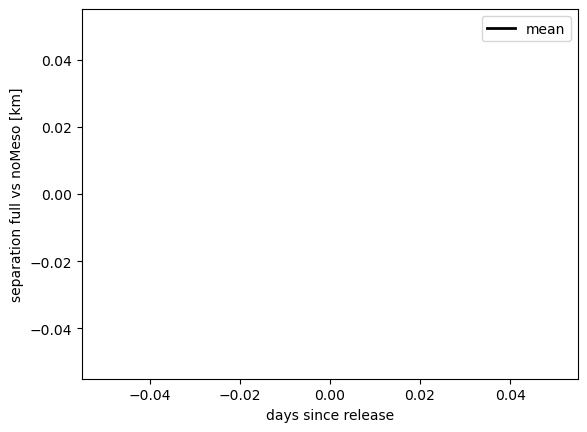

In [13]:
# separation between the same particle in both runs, over time
R = 6371.0  # km
lat1, lon1 = np.deg2rad(ds["full"].lat), np.deg2rad(ds["full"].lon)
lat2, lon2 = np.deg2rad(ds["noMeso"].lat), np.deg2rad(ds["noMeso"].lon)
a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
sep = 2 * R * np.arcsin(np.sqrt(a))          # (trajectory, obs), km

days = np.arange(sep.sizes["obs"]) * out_put_step_hours / 24
plt.plot(days, sep.T, color='gray', lw=0.3)
plt.plot(days, sep.mean('trajectory'), color='k', lw=2, label='mean')
plt.xlabel('days since release')
plt.ylabel('separation full vs noMeso [km]')
plt.legend()
plt.show()

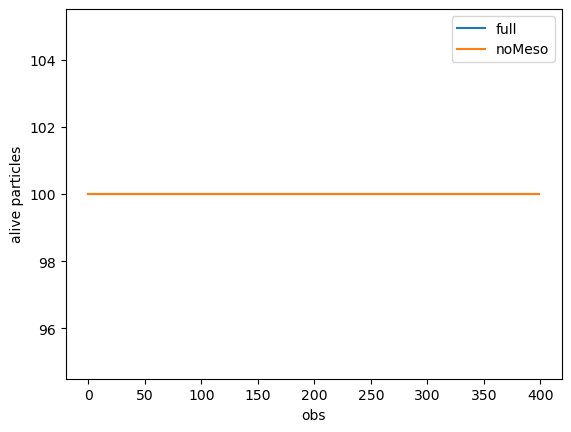

In [14]:
# particles still alive in each run
for name, d in ds.items():
    d.lat.notnull().sum('trajectory').plot(label=name)
plt.ylabel('alive particles')
plt.legend()
plt.show()